
NONLINEAR MODEL - Learning Rate = 0.1
Epoch  500 | Loss = 2.090720
Epoch 1000 | Loss = 2.090720
Epoch 1500 | Loss = 2.090720
Epoch 2000 | Loss = 2.090720
Epoch 2500 | Loss = 2.090720
Epoch 3000 | Loss = 2.090720
Epoch 3500 | Loss = 2.090720
Epoch 4000 | Loss = 2.090720
Epoch 4500 | Loss = 2.090720
Epoch 5000 | Loss = 2.090720

NONLINEAR MODEL - Learning Rate = 0.01
Epoch  500 | Loss = 2.091763
Epoch 1000 | Loss = 2.090720
Epoch 1500 | Loss = 2.090720
Epoch 2000 | Loss = 2.090720
Epoch 2500 | Loss = 2.090720
Epoch 3000 | Loss = 2.090720
Epoch 3500 | Loss = 2.090720
Epoch 4000 | Loss = 2.090720
Epoch 4500 | Loss = 2.090720
Epoch 5000 | Loss = 2.090720

NONLINEAR MODEL - Learning Rate = 0.001
Epoch  500 | Loss = 25.546222
Epoch 1000 | Loss = 7.704160
Epoch 1500 | Loss = 3.731461
Epoch 2000 | Loss = 2.628518
Epoch 2500 | Loss = 2.276634
Epoch 3000 | Loss = 2.156412
Epoch 3500 | Loss = 2.114131
Epoch 4000 | Loss = 2.099090
Epoch 4500 | Loss = 2.093717
Epoch 5000 | Loss = 2.091793

NONLINEA

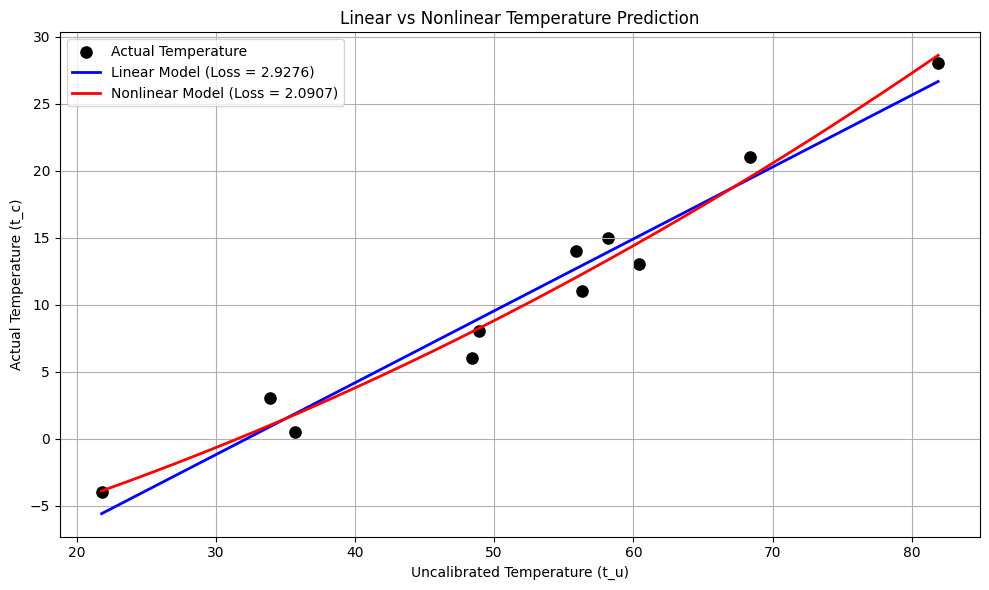


PROBLEM 1.c - FINAL COMPARISON
Best Linear Loss    = 2.927646
Best Nonlinear Loss = 2.090720
Conclusion: The nonlinear model performs BETTER than the linear baseline.


In [2]:

import torch
import matplotlib.pyplot as plt

# ============================================================
# Temperature prediction dataset (lecture example)
# ============================================================

t_c = torch.tensor(
    [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0],
    dtype=torch.float64
)

t_u = torch.tensor(
    [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4],
    dtype=torch.float64
)

# Standardize inputs to prevent gradient divergence
t_mean = t_u.mean()
t_std = t_u.std(unbiased=False)
t_un = (t_u - t_mean) / t_std


# ============================================================
# Problem 1.a - Nonlinear model and modified training loop
# ============================================================

def model_nonlinear(t_u, w2, w1, b):
    return w2 * t_u**2 + w1 * t_u + b


def model_linear(t_u, w, b):
    return w * t_u + b


def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()


def training_loop(n_epochs, learning_rate, params, t_u, t_c,
                  model, show_loss=True):

    for epoch in range(1, n_epochs + 1):

        if params.grad is not None:
            params.grad.zero_()

        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        loss.backward()

        with torch.no_grad():
            params -= learning_rate * params.grad

        if show_loss and epoch % 500 == 0:
            print(f"Epoch {epoch:4d} | Loss = {loss.item():.6f}")

    with torch.no_grad():
        final_loss = loss_fn(model(t_u, *params), t_c).item()

    return params.detach().clone(), final_loss


# ============================================================
# Problem 1.b - Four learning rates, 5000 epochs each
# ============================================================

learning_rates = [0.1, 0.01, 0.001, 0.0001]
results = {}

for lr in learning_rates:

    print(f"\n{'=' * 50}")
    print(f"NONLINEAR MODEL - Learning Rate = {lr}")
    print(f"{'=' * 50}")

    params = torch.tensor(
        [0.0, 0.0, 0.0],
        dtype=torch.float64,
        requires_grad=True
    )

    final_params, final_loss = training_loop(
        n_epochs=5000,
        learning_rate=lr,
        params=params,
        t_u=t_un,
        t_c=t_c,
        model=model_nonlinear
    )

    results[lr] = {
        "params": final_params,
        "loss": final_loss
    }


# Select the best nonlinear model
best_lr = min(results, key=lambda lr: results[lr]["loss"])
best_params = results[best_lr]["params"]
best_loss = results[best_lr]["loss"]

print(f"\n{'=' * 50}")
print("NONLINEAR MODEL - FINAL RESULTS")
print(f"{'=' * 50}")

for lr in learning_rates:
    print(f"Learning Rate = {lr:<7} | Final Loss = {results[lr]['loss']:.6f}")

print(f"\nBest Learning Rate = {best_lr}")
print(f"Best Nonlinear Loss = {best_loss:.6f}")

# Convert coefficients back to original t_u units
a, c, d = best_params.tolist()
mu = t_mean.item()
sigma = t_std.item()

w2 = a / sigma**2
w1 = c / sigma - 2 * a * mu / sigma**2
b = a * mu**2 / sigma**2 - c * mu / sigma + d

print("\nBest Nonlinear Model (original temperature units):")
print(f"w2 = {w2:.8f}")
print(f"w1 = {w1:.8f}")
print(f"b  = {b:.8f}")


# ============================================================
# Problem 1.c - Train lecture's linear baseline
# ============================================================

print(f"\n{'=' * 50}")
print("LINEAR BASELINE MODEL")
print(f"{'=' * 50}")

linear_params = torch.tensor(
    [0.0, 0.0],
    dtype=torch.float64,
    requires_grad=True
)

linear_params, linear_loss = training_loop(
    n_epochs=5000,
    learning_rate=0.1,
    params=linear_params,
    t_u=t_un,
    t_c=t_c,
    model=model_linear,
    show_loss=False
)

print(f"Linear Model Final Loss = {linear_loss:.6f}")
print(f"Nonlinear Model Best Loss = {best_loss:.6f}")


# ============================================================
# Problem 1.c - Visualize linear vs nonlinear models
# ============================================================

t_u_plot = torch.linspace(
    t_u.min().item(),
    t_u.max().item(),
    200,
    dtype=torch.float64
)

t_un_plot = (t_u_plot - t_mean) / t_std

with torch.no_grad():
    linear_predictions = model_linear(
        t_un_plot, *linear_params
    )

    nonlinear_predictions = model_nonlinear(
        t_un_plot, *best_params
    )

plt.figure(figsize=(10, 6))

plt.scatter(
    t_u.numpy(),
    t_c.numpy(),
    color="black",
    s=65,
    label="Actual Temperature"
)

plt.plot(
    t_u_plot.numpy(),
    linear_predictions.numpy(),
    color="blue",
    linewidth=2,
    label=f"Linear Model (Loss = {linear_loss:.4f})"
)

plt.plot(
    t_u_plot.numpy(),
    nonlinear_predictions.numpy(),
    color="red",
    linewidth=2,
    label=f"Nonlinear Model (Loss = {best_loss:.4f})"
)

plt.xlabel("Uncalibrated Temperature (t_u)")
plt.ylabel("Actual Temperature (t_c)")
plt.title("Linear vs Nonlinear Temperature Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# Problem 1.c - Final comparison and conclusion
# ============================================================

print(f"\n{'=' * 50}")
print("PROBLEM 1.c - FINAL COMPARISON")
print(f"{'=' * 50}")

print(f"Best Linear Loss    = {linear_loss:.6f}")
print(f"Best Nonlinear Loss = {best_loss:.6f}")

if best_loss < linear_loss:
    print("Conclusion: The nonlinear model performs BETTER than the linear baseline.")
elif best_loss > linear_loss:
    print("Conclusion: The nonlinear model performs WORSE than the linear baseline.")
else:
    print("Conclusion: Both models have the same loss.")
